<a href="https://colab.research.google.com/github/Deshawa77/pusl3123-a1/blob/main/Exercise2_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import os
os.chdir("/content/drive/MyDrive/pusl3123-a1")
print(os.getcwd(), os.listdir("."))

Mounted at /content/drive
/content/drive/MyDrive/pusl3123-a1 ['split.npy', 'results', 'figures', 'Exercise2_CNN.ipynb']


In [2]:
import sys, random, json, time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.14.1+cu130


In [3]:
MEAN = (0.49181848764419556, 0.4826730489730835, 0.44718557596206665)
STD  = (0.246906116604805, 0.2434273362159729, 0.2615409195423126)

base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
full_clean = torchvision.datasets.CIFAR10("/content/data", train=True,  download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("/content/data", train=False, download=True, transform=base_tf)

perm = np.load("split.npy")                       # the shared fixed split from setup
train_idx, val_idx = perm[:45000].tolist(), perm[45000:].tolist()
assert len(set(train_idx) & set(val_idx)) == 0

BATCH = 128
g = torch.Generator(); g.manual_seed(42)
train_loader      = DataLoader(Subset(full_clean, train_idx), batch_size=BATCH, shuffle=True, generator=g)
train_loader_eval = DataLoader(Subset(full_clean, train_idx), batch_size=512, shuffle=False)
val_loader        = DataLoader(Subset(full_clean, val_idx),   batch_size=512, shuffle=False)
test_loader       = DataLoader(test_set, batch_size=512, shuffle=False)   # used ONLY in the final cell
print(len(train_idx), len(val_idx), len(test_set))

100%|██████████| 170M/170M [30:48<00:00, 92.2kB/s]


45000 5000 10000


In [4]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total_loss += crit(out, yb).item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        n += xb.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=30, lr=1e-3, name="run"):
    model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "epoch_time"]}
    best_val_loss, best_state, best_epoch = float("inf"), None, -1
    for ep in range(epochs):
        t0 = time.time(); model.train()
        run_loss, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            run_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
        vl, va = evaluate(model, val_loader)
        hist["train_loss"].append(run_loss / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl);             hist["val_acc"].append(va)
        hist["epoch_time"].append(time.time() - t0)
        if vl < best_val_loss:                      # selection uses VALIDATION loss only
            best_val_loss, best_epoch = vl, ep
            best_state = copy.deepcopy(model.state_dict())
        print(f"[{name}] ep {ep+1:02d} | train {run_loss/n:.3f}/{correct/n:.3f} | val {vl:.3f}/{va:.3f}")
    model.load_state_dict(best_state)               # restore best-validation weights
    hist.update(best_epoch=best_epoch, params=count_params(model), name=name)
    return hist

def save_history(hist, name):
    with open(f"results/{name}.json", "w") as f:
        json.dump(hist, f)

In [5]:
class MLP(nn.Module):                      # identical to Exercise 1, needed to reload its weights
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(),
            nn.Linear(3072, 512), nn.ReLU(),
            nn.Linear(512, 256),  nn.ReLU(),
            nn.Linear(256, 10))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32x32 -> 16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16x16 -> 8x8
        )
        self.classifier = nn.Linear(64 * 8 * 8, 10)                         # third trainable layer
    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

set_seed(42)
cnn = CNN()
print(cnn)
print("trainable params:", count_params(cnn))

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Linear(in_features=4096, out_features=10, bias=True)
)
trainable params: 60362


In [6]:
set_seed(42)
cnn = CNN()
hist_cnn = fit(cnn, train_loader, val_loader, epochs=30, lr=1e-3, name="cnn")
save_history(hist_cnn, "cnn")
torch.save(cnn.state_dict(), "results/cnn.pt")     # Exercise 3 and 4 baselines can check against this
print("best epoch:", hist_cnn["best_epoch"] + 1)

[cnn] ep 01 | train 1.402/0.503 | val 1.145/0.606
[cnn] ep 02 | train 1.030/0.641 | val 1.019/0.649
[cnn] ep 03 | train 0.907/0.686 | val 0.942/0.678
[cnn] ep 04 | train 0.818/0.718 | val 0.885/0.701
[cnn] ep 05 | train 0.756/0.740 | val 0.875/0.710
[cnn] ep 06 | train 0.697/0.760 | val 0.870/0.711
[cnn] ep 07 | train 0.656/0.774 | val 0.866/0.721
[cnn] ep 08 | train 0.606/0.791 | val 0.860/0.721
[cnn] ep 09 | train 0.574/0.803 | val 0.921/0.707
[cnn] ep 10 | train 0.543/0.814 | val 0.897/0.715
[cnn] ep 11 | train 0.509/0.823 | val 0.925/0.710
[cnn] ep 12 | train 0.483/0.833 | val 0.929/0.716
[cnn] ep 13 | train 0.458/0.841 | val 0.970/0.707
[cnn] ep 14 | train 0.429/0.852 | val 0.988/0.712
[cnn] ep 15 | train 0.411/0.857 | val 0.987/0.711
[cnn] ep 16 | train 0.382/0.869 | val 0.996/0.718
[cnn] ep 17 | train 0.366/0.871 | val 1.054/0.710
[cnn] ep 18 | train 0.350/0.879 | val 1.070/0.709
[cnn] ep 19 | train 0.331/0.885 | val 1.083/0.706
[cnn] ep 20 | train 0.314/0.889 | val 1.122/0.708


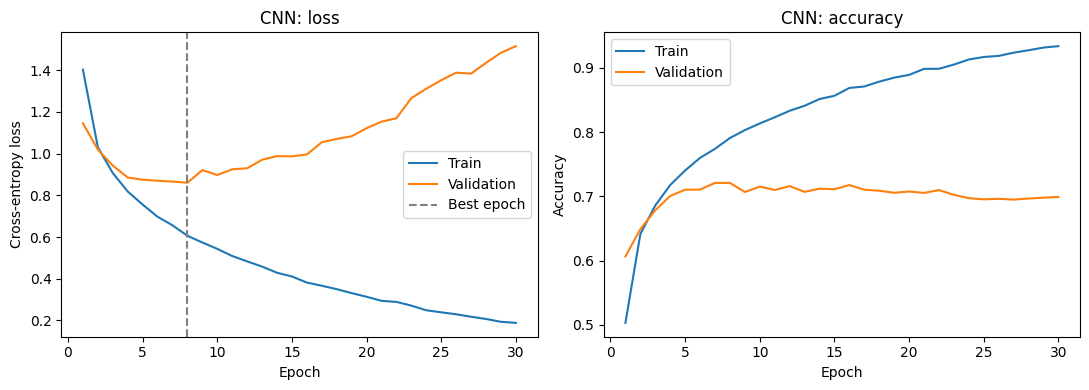

In [7]:
def plot_curves(hist, title, fname):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, hist["train_loss"], label="Train"); ax[0].plot(ep, hist["val_loss"], label="Validation")
    ax[0].axvline(hist["best_epoch"] + 1, ls="--", c="grey", label="Best epoch")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].set_title(f"{title}: loss"); ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="Train"); ax[1].plot(ep, hist["val_acc"], label="Validation")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title(f"{title}: accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"figures/{fname}.png", dpi=200); plt.show()

plot_curves(hist_cnn, "CNN", "cnn_curves")

In [8]:
mlp = MLP().to(device)
mlp.load_state_dict(torch.load("results/mlp.pt", map_location=device))
with open("results/mlp.json") as f: hist_mlp = json.load(f)
print("MLP params:", count_params(mlp), "| best epoch:", hist_mlp["best_epoch"] + 1)

MLP params: 1707274 | best epoch: 4


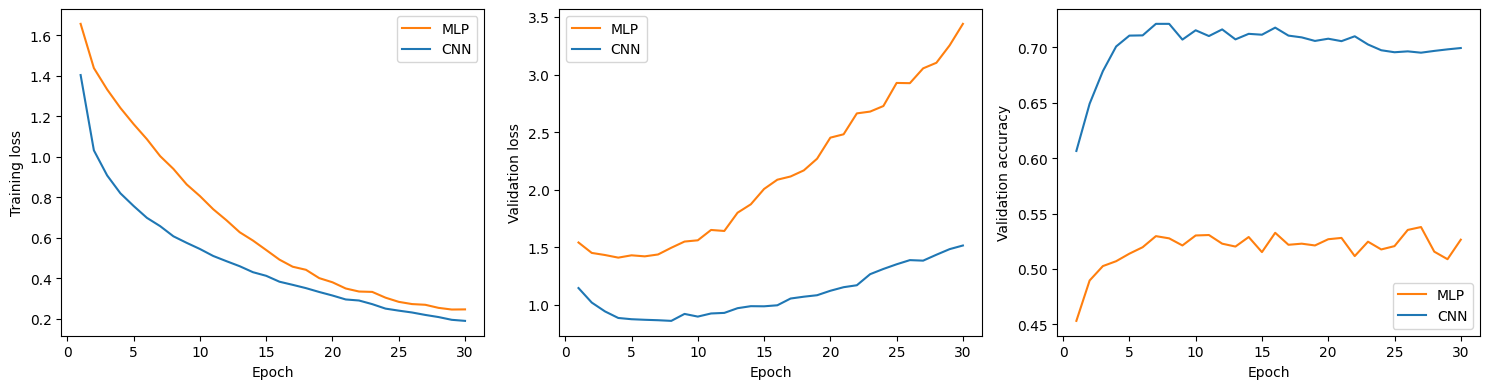

In [9]:
ep = range(1, 31)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for h, lab, c in [(hist_mlp, "MLP", "tab:orange"), (hist_cnn, "CNN", "tab:blue")]:
    ax[0].plot(ep, h["train_loss"], c=c, label=lab)
    ax[1].plot(ep, h["val_loss"],   c=c, label=lab)
    ax[2].plot(ep, h["val_acc"],    c=c, label=lab)
ax[0].set_ylabel("Training loss"); ax[1].set_ylabel("Validation loss"); ax[2].set_ylabel("Validation accuracy")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.savefig("figures/ex2_mlp_vs_cnn.png", dpi=200); plt.show()

In [10]:
def summarise(model, hist, name):
    _, tr = evaluate(model, train_loader_eval)      # clean train set, eval mode
    _, va = evaluate(model, val_loader)
    _, te = evaluate(model, test_loader)
    return dict(Model=name, Params=count_params(model),
                BestEpoch=hist["best_epoch"] + 1,
                TrainAcc=round(tr, 4), ValAcc=round(va, 4), TestAcc=round(te, 4),
                Gap=round(tr - te, 4),
                MinValLoss=round(min(hist["val_loss"]), 3),
                SecPerEpoch=round(float(np.mean(hist["epoch_time"])), 1))

table = pd.DataFrame([summarise(mlp, hist_mlp, "MLP"), summarise(cnn, hist_cnn, "CNN")])
print(table.to_string(index=False))
print("Parameter ratio MLP/CNN:", round(count_params(mlp) / count_params(cnn), 1))
table.to_csv("results/ex2_comparison.csv", index=False)

Model  Params  BestEpoch  TrainAcc  ValAcc  TestAcc    Gap  MinValLoss  SecPerEpoch
  MLP 1707274          4    0.5980   0.507   0.5095 0.0885        1.41         11.6
  CNN   60362          8    0.8205   0.721   0.7164 0.1041        0.86         13.9
Parameter ratio MLP/CNN: 28.3


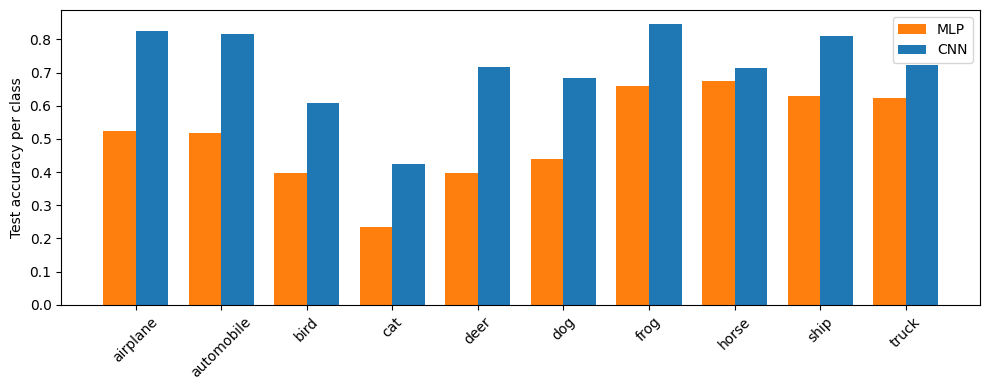

In [11]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); P, L = [], []
    for xb, yb in loader:
        P.append(model(xb.to(device)).argmax(1).cpu()); L.append(yb)
    return torch.cat(P).numpy(), torch.cat(L).numpy()

classes = test_set.classes
per_class = {}
for name, m in [("MLP", mlp), ("CNN", cnn)]:
    p, l = predict(m, test_loader)
    per_class[name] = [(p[l == c] == c).mean() for c in range(10)]

x = np.arange(10); w = 0.38
plt.figure(figsize=(10, 4))
plt.bar(x - w/2, per_class["MLP"], w, label="MLP", color="tab:orange")
plt.bar(x + w/2, per_class["CNN"], w, label="CNN", color="tab:blue")
plt.xticks(x, classes, rotation=45); plt.ylabel("Test accuracy per class"); plt.legend()
plt.tight_layout(); plt.savefig("figures/ex2_per_class.png", dpi=200); plt.show()

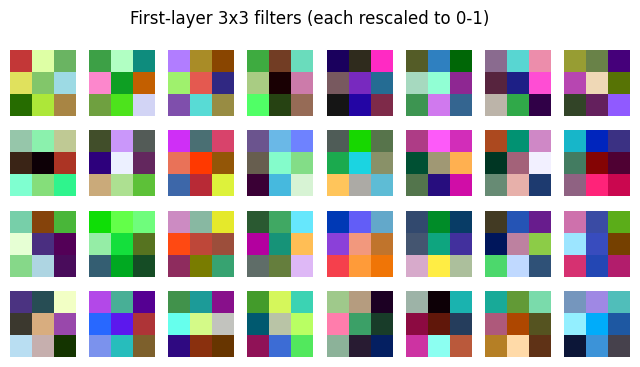

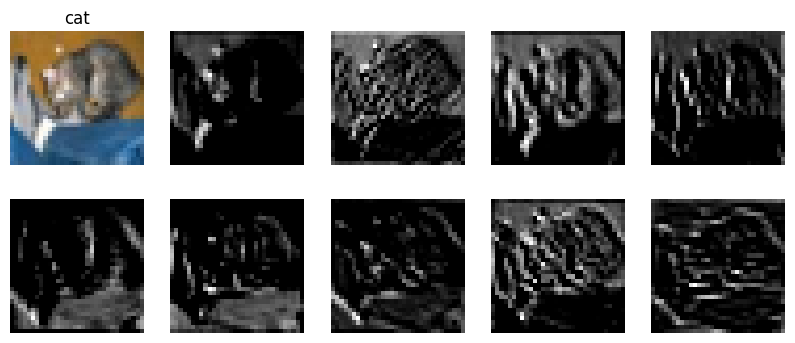

In [12]:
w = cnn.features[0].weight.detach().cpu()                        # (32, 3, 3, 3)
w = (w - w.amin(dim=(1, 2, 3), keepdim=True)) / (w.amax(dim=(1, 2, 3), keepdim=True) - w.amin(dim=(1, 2, 3), keepdim=True))
fig, axes = plt.subplots(4, 8, figsize=(8, 4))
for ax, f in zip(axes.flat, w):
    ax.imshow(f.permute(1, 2, 0)); ax.axis("off")
plt.suptitle("First-layer 3x3 filters (each rescaled to 0-1)")
plt.savefig("figures/ex2_filters.png", dpi=200); plt.show()

img, lab = test_set[0]
with torch.no_grad():
    fm = cnn.features[1](cnn.features[0](img.unsqueeze(0).to(device))).cpu()[0]   # after conv1 + ReLU
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
axes[0, 0].imshow((img * std + mean).permute(1, 2, 0).clamp(0, 1)); axes[0, 0].set_title(classes[lab]);
for i, ax in enumerate(list(axes.flat)[1:]):
    ax.imshow(fm[i], cmap="gray")
for ax in axes.flat: ax.axis("off")
plt.savefig("figures/ex2_feature_maps.png", dpi=200); plt.show()